# Adversarial Cropping — crop grid preview

This notebook previews a few images from the shared analysis manifest and all 20 fixed crop conditions. Crops are created on the original PIL RGB image before any model preprocessing.

This is a visualization notebook only: it does not load models, run inference, or create final metrics.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd

repo_root = Path.cwd()
if not (repo_root / 'src').is_dir():
    repo_root = repo_root.parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.data import iter_analysis_images, load_analysis_manifest
from experiments.adversarial_cropping.crop_utils import iter_crop_conditions

## Load five preview images

The first five manifest records are used only for visualization. They are not a representative research cohort.

In [2]:
records = load_analysis_manifest(limit=5)
samples = list(iter_analysis_images(records))
assert len(samples) == 5
[(image_id, image.size, label, image.mode) for image, label, image_id in samples]

[('ILSVRC2012_val_00000015_n03496892.JPEG', (620, 478), 595, 'RGB'),
 ('ILSVRC2012_val_00000011_n01917289.JPEG', (500, 400), 109, 'RGB'),
 ('ILSVRC2012_val_00000014_n04065272.JPEG', (500, 376), 757, 'RGB'),
 ('ILSVRC2012_val_00000005_n03125729.JPEG', (500, 333), 516, 'RGB'),
 ('ILSVRC2012_val_00000029_n01729977.JPEG', (500, 334), 55, 'RGB')]

## Display the first image and its 20 crop conditions

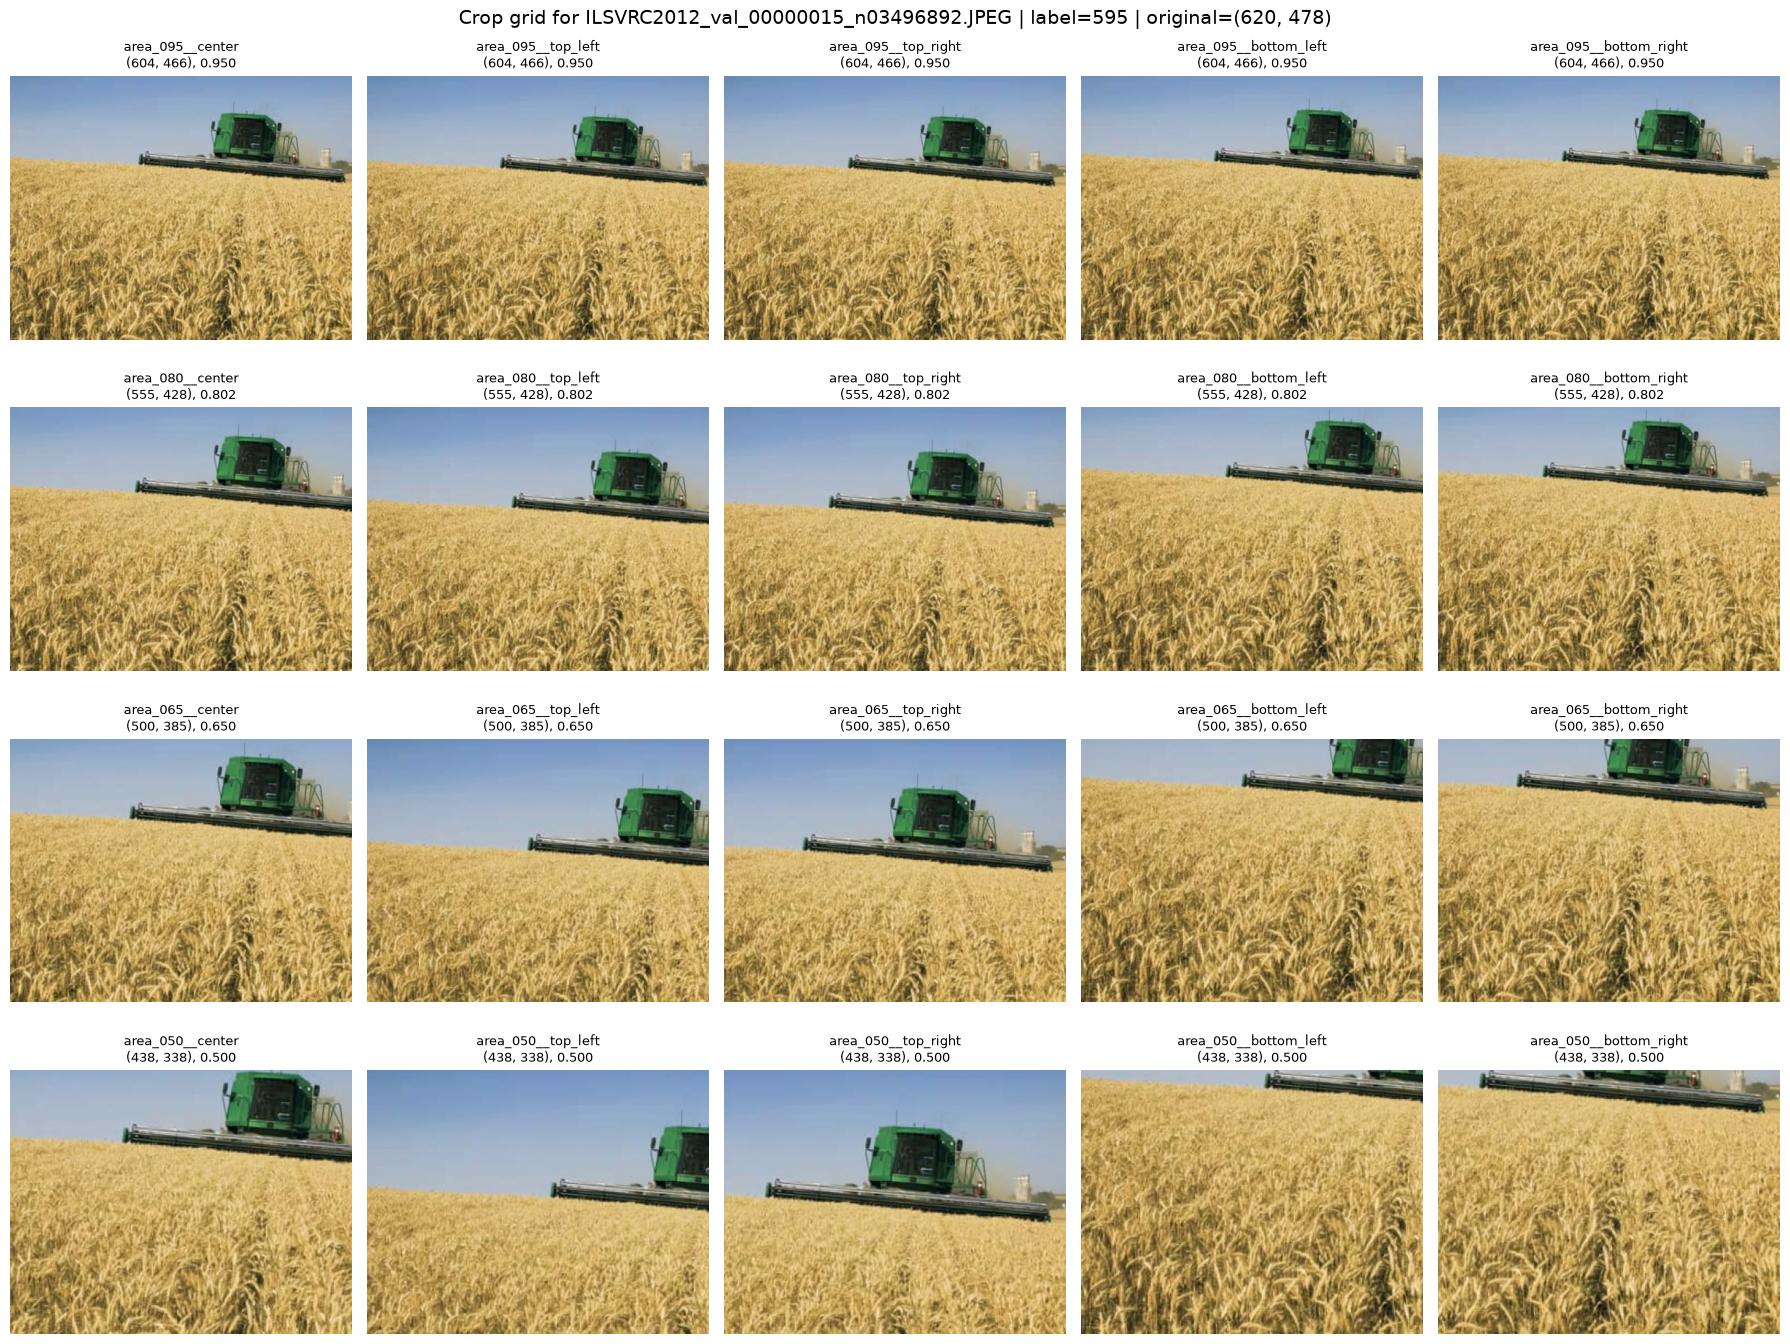

In [3]:
image, label, image_id = samples[0]
results = list(iter_crop_conditions(image))

fig, axes = plt.subplots(4, 5, figsize=(18, 14))
for axis, result in zip(axes.flat, results):
    axis.imshow(result.image)
    axis.set_title(f'{result.condition}\n{result.crop_size}, {result.realized_area_ratio:.3f}', fontsize=9)
    axis.axis('off')
fig.suptitle(f'Crop grid for {image_id} | label={label} | original={image.size}', fontsize=14)
fig.tight_layout()
plt.show()

## Crop geometry table

In [4]:
geometry_rows = []
for image, label, image_id in samples:
    for result in iter_crop_conditions(image):
        geometry_rows.append({
            'image_id': image_id,
            'label': label,
            'condition': result.condition,
            'severity': result.severity,
            'original_size': result.original_size,
            'crop_size': result.crop_size,
            'box_left_top_right_bottom': result.box,
            'realized_area_ratio': result.realized_area_ratio,
        })

geometry = pd.DataFrame(geometry_rows)
geometry.head(20)

,image_id,label,condition,severity,original_size,crop_size,box_left_top_right_bottom,realized_area_ratio
0,ILSVRC2012_val_00000015_n03496892.JPEG,595,area_095__center,0.95,"(620, 478)","(604, 466)","(8, 6, 612, 472)",0.949737
1,ILSVRC2012_val_00000015_n03496892.JPEG,595,area_095__top_left,0.95,"(620, 478)","(604, 466)","(0, 0, 604, 466)",0.949737
2,ILSVRC2012_val_00000015_n03496892.JPEG,595,area_095__top_right,0.95,"(620, 478)","(604, 466)","(16, 0, 620, 466)",0.949737
3,ILSVRC2012_val_00000015_n03496892.JPEG,595,area_095__bottom_left,0.95,"(620, 478)","(604, 466)","(0, 12, 604, 478)",0.949737
4,ILSVRC2012_val_00000015_n03496892.JPEG,595,area_095__bottom_right,0.95,"(620, 478)","(604, 466)","(16, 12, 620, 478)",0.949737
5,ILSVRC2012_val_00000015_n03496892.JPEG,595,area_080__center,0.80,"(620, 478)","(555, 428)","(32, 25, 587, 453)",0.801525
6,ILSVRC2012_val_00000015_n03496892.JPEG,595,area_080__top_left,0.80,"(620, 478)","(555, 428)","(0, 0, 555, 428)",0.801525
7,ILSVRC2012_val_00000015_n03496892.JPEG,595,area_080__top_right,0.80,"(620, 478)","(555, 428)","(65, 0, 620, 428)",0.801525
8,ILSVRC2012_val_00000015_n03496892.JPEG,595,area_080__bottom_left,0.80,"(620, 478)","(555, 428)","(0, 50, 555, 478)",0.801525
9,ILSVRC2012_val_00000015_n03496892.JPEG,595,area_080__bottom_right,0.80,"(620, 478)","(555, 428)","(65, 50, 620, 478)",0.801525


## Compare the same crop grid across the five preview images

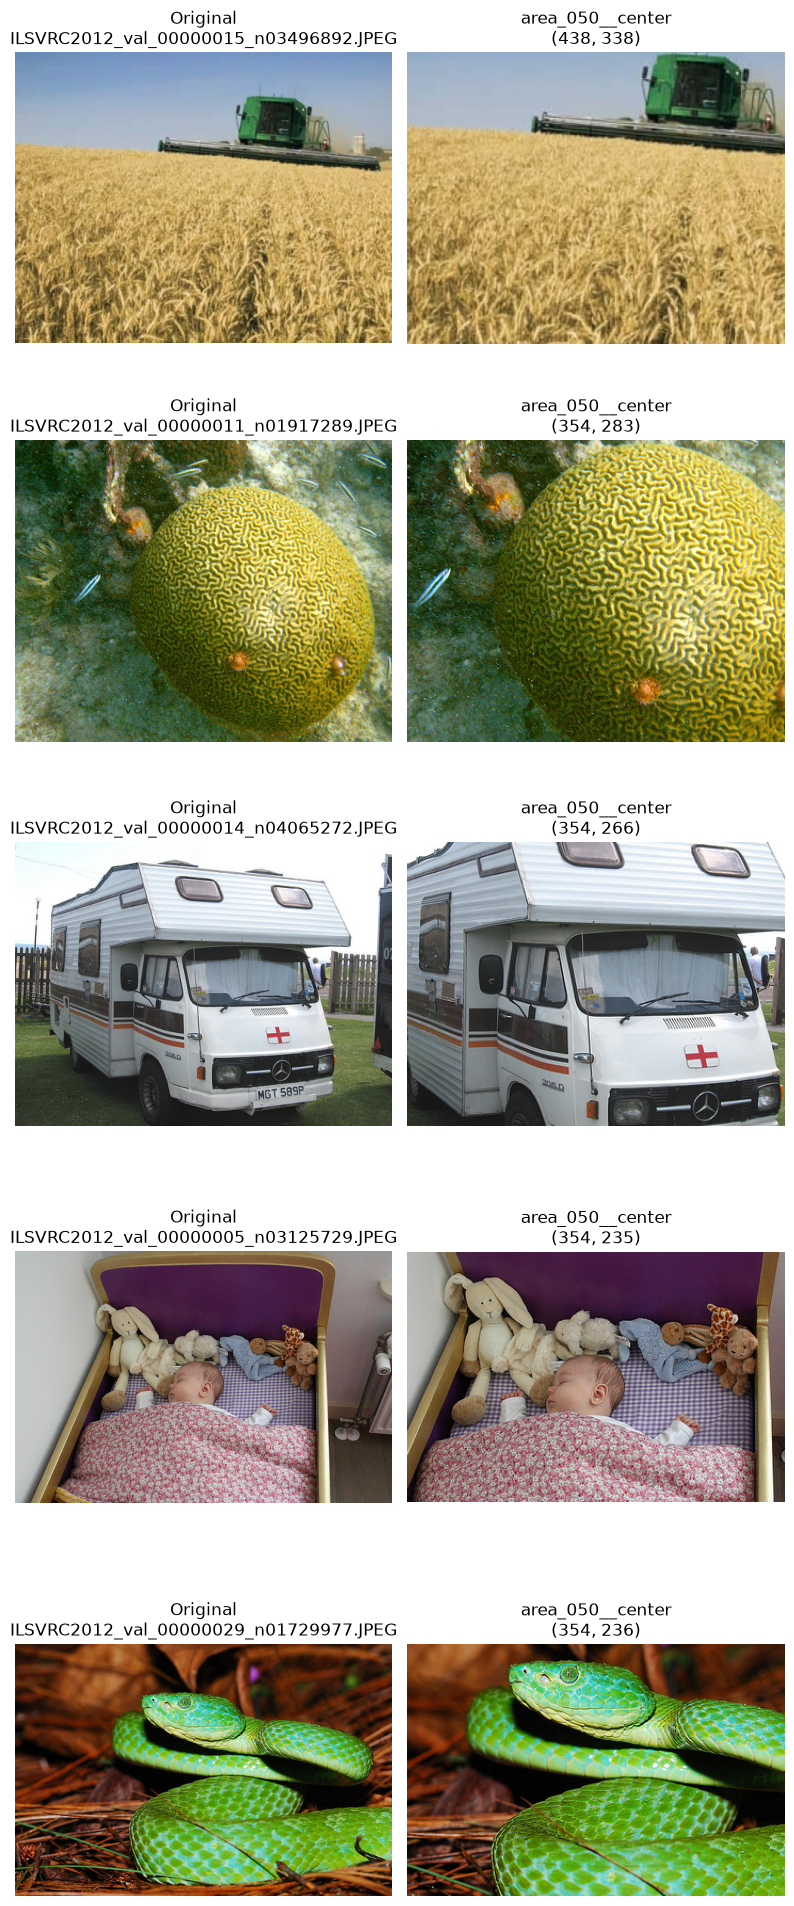

In [5]:
fig, axes = plt.subplots(len(samples), 2, figsize=(8, 4 * len(samples)))
for row, (image, label, image_id) in enumerate(samples):
    center_crop = next(result for result in iter_crop_conditions(image) if result.condition == 'area_050__center')
    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f'Original\n{image_id}')
    axes[row, 1].imshow(center_crop.image)
    axes[row, 1].set_title(f'area_050__center\n{center_crop.crop_size}')
    axes[row, 0].axis('off')
    axes[row, 1].axis('off')
fig.tight_layout()
plt.show()

## Clean baseline results on the 10,000-image analysis cohort

The notebook automatically selects the most recently modified Phase 2 `intermediate/clean_metrics.csv`. These accuracies are calculated on the shared 10,000-image cohort, not copied from the full 50K baseline accuracy.

In [6]:
experiment_root = repo_root / 'results/metrics/experiments/adversarial_cropping'
clean_metric_files = list(experiment_root.glob('*/intermediate/clean_metrics.csv'))
if not clean_metric_files:
    raise FileNotFoundError('No Phase 2 clean_metrics.csv found')
clean_metrics_path = max(clean_metric_files, key=lambda path: path.stat().st_mtime)
clean_run_dir = clean_metrics_path.parent
clean_metrics = pd.read_csv(clean_metrics_path)
print(f'Run: {clean_run_dir.parent.name}')
display(clean_metrics)

Run: main10000_clean_v1_20261105_153202_9544b43


,model_name,cohort,num_images,top1_accuracy_percent,top5_accuracy_percent,prediction_source
0,resnet50,analysis_10000_seed42,10000,80.82,95.40,baseline
1,vit_b_16,analysis_10000_seed42,10000,80.75,95.31,baseline


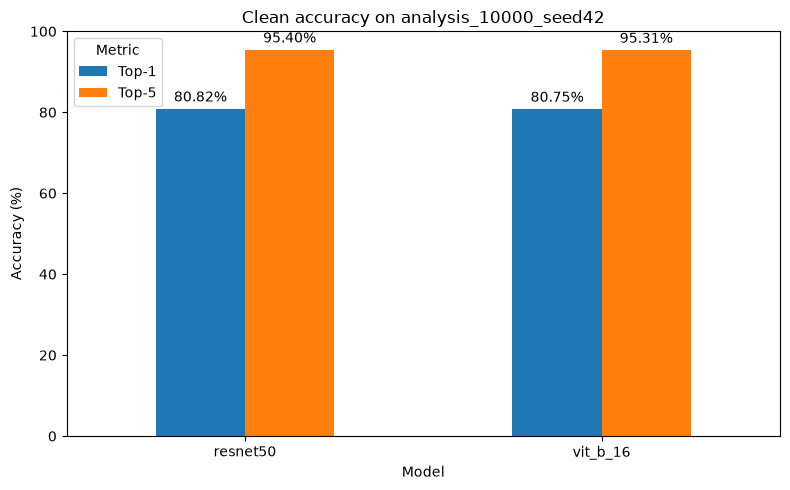

In [7]:
accuracy_plot = clean_metrics.set_index('model_name')[
    ['top1_accuracy_percent', 'top5_accuracy_percent']
].rename(columns={
    'top1_accuracy_percent': 'Top-1',
    'top5_accuracy_percent': 'Top-5',
})
axis = accuracy_plot.plot(kind='bar', figsize=(8, 5), rot=0, ylim=(0, 100))
axis.set_title('Clean accuracy on analysis_10000_seed42')
axis.set_xlabel('Model')
axis.set_ylabel('Accuracy (%)')
axis.legend(title='Metric')
for container in axis.containers:
    axis.bar_label(container, fmt='%.2f%%', padding=3)
plt.tight_layout()
plt.show()

### Cohort and run metadata

In [8]:
clean_metadata = json.loads((clean_run_dir / 'metadata.json').read_text(encoding='utf-8'))
cohort_summary = pd.DataFrame([{
    'run_id': clean_metadata['run_id'],
    'cohort': clean_metadata['cohort']['name'],
    'num_images': clean_metadata['cohort']['num_images'],
    'prediction_source': clean_metadata['prediction_source'],
    'manifest_sha256_lf': clean_metadata['cohort']['manifest_sha256_lf'],
    'git_revision': clean_metadata['git_revision'][:7],
}])
display(cohort_summary)

,run_id,cohort,num_images,prediction_source,manifest_sha256_lf,git_revision
0,main10000_clean_v1_20261105_153202_9544b43,analysis_10000_seed42,10000,baseline,eea185ba9e733636eb245c8d4eab3137f91af4be3d9a5f...,9544b43


### Sample clean predictions from both models

In [9]:
resnet_clean = pd.read_csv(clean_run_dir / 'resnet50_clean_predictions.csv')
vit_clean = pd.read_csv(clean_run_dir / 'vit_b_16_clean_predictions.csv')
prediction_comparison = resnet_clean[[
    'image_id', 'label', 'pred_top1', 'top1_correct'
]].merge(
    vit_clean[['image_id', 'label', 'pred_top1', 'top1_correct']],
    on=['image_id', 'label'],
    validate='one_to_one',
    suffixes=('_resnet50', '_vit_b_16'),
)
preview_ids = [image_id for _, _, image_id in samples]
display(prediction_comparison[prediction_comparison.image_id.isin(preview_ids)])

,image_id,label,pred_top1_resnet50,top1_correct_resnet50,pred_top1_vit_b_16,top1_correct_vit_b_16
0,ILSVRC2012_val_00000005_n03125729.JPEG,516,516,1,520,0
1,ILSVRC2012_val_00000011_n01917289.JPEG,109,109,1,109,1
2,ILSVRC2012_val_00000014_n04065272.JPEG,757,757,1,757,1
3,ILSVRC2012_val_00000015_n03496892.JPEG,595,595,1,595,1
4,ILSVRC2012_val_00000029_n01729977.JPEG,55,55,1,55,1


## How cropping reduces prediction accuracy

Both models receive the same 10,000 images and the same crop at each retained-area level. The charts use accuracy percentages so the effect is easy to read: moving from 100% (clean) toward 50% retained area removes more of the original image.

In [10]:
final_metric_files = list(experiment_root.glob('*/final/metrics.csv'))
if not final_metric_files:
    raise FileNotFoundError('No final metrics.csv found. Run analyze_results.py first.')
final_metrics_path = max(final_metric_files, key=lambda path: path.stat().st_mtime)
main_run_dir = final_metrics_path.parent
main_run_id = main_run_dir.parent.name
metrics = pd.read_csv(final_metrics_path)
severity_metrics = pd.read_csv(main_run_dir / 'severity_metrics.csv')
assert len(metrics) == 40
assert set(metrics.model_name) == {'resnet50', 'vit_b_16'}
print('Run:', main_run_id)
print('Conditions per model:', metrics.groupby('model_name').size().to_dict())

Run: main10000_grid_kaggle_gpu_v1_20261106_9544b43
Conditions per model: {'resnet50': 20, 'vit_b_16': 20}


### Top-1 and Top-5 accuracy as more of the image is removed

Each cropped value is the average across the five shared crop positions. The clean bar is the same 10,000-image cohort before cropping.

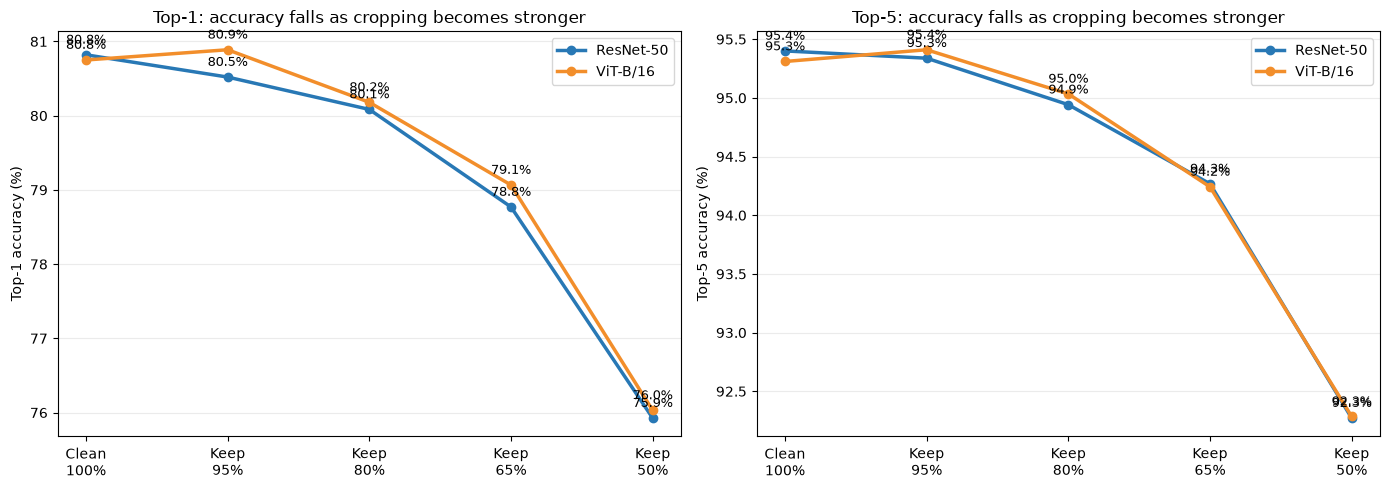

In [11]:
model_order = ['resnet50', 'vit_b_16']
model_labels = {'resnet50': 'ResNet-50', 'vit_b_16': 'ViT-B/16'}
colors = {'resnet50': '#2878B5', 'vit_b_16': '#F28E2B'}
severity_order = [0.95, 0.80, 0.65, 0.50]
x_labels = ['Clean\n100%', 'Keep\n95%', 'Keep\n80%', 'Keep\n65%', 'Keep\n50%']
x = range(len(x_labels))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for axis, top_k in zip(axes, [1, 5]):
    for model_name in model_order:
        model = severity_metrics[severity_metrics.model_name == model_name].set_index('severity')
        values = [model[f'clean_top{top_k}_accuracy_percent'].iloc[0]] + [
            model.loc[severity, f'perturbed_top{top_k}_accuracy_percent']
            for severity in severity_order
        ]
        axis.plot(x, values, marker='o', linewidth=2.5, label=model_labels[model_name], color=colors[model_name])
        for index, value in enumerate(values):
            axis.annotate(f'{value:.1f}%', (index, value), xytext=(0, 8), textcoords='offset points', ha='center', fontsize=9)
    axis.set_xticks(list(x), x_labels)
    axis.set_ylabel(f'Top-{top_k} accuracy (%)')
    axis.set_title(f'Top-{top_k}: accuracy falls as cropping becomes stronger')
    axis.grid(axis='y', alpha=0.25)
    axis.legend()
plt.tight_layout()

### Relative loss of correct predictions

This chart answers: compared with each model's own clean accuracy, what percentage of that accuracy is lost after cropping? A negative value means a very small improvement rather than a loss.

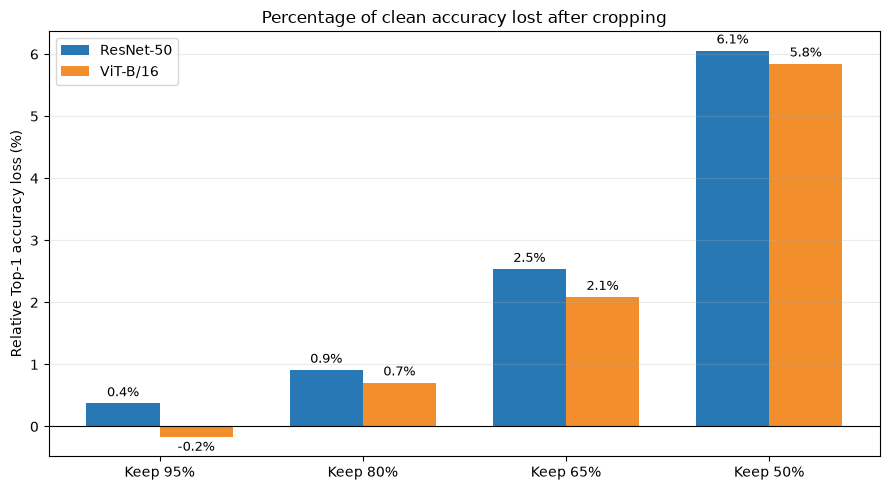

In [12]:
bar_width = 0.36
positions = list(range(len(severity_order)))
fig, axis = plt.subplots(figsize=(9, 5))
for offset, model_name in zip([-bar_width / 2, bar_width / 2], model_order):
    model = severity_metrics[severity_metrics.model_name == model_name].set_index('severity')
    values = [model.loc[severity, 'relative_top1_drop_percent'] for severity in severity_order]
    bars = axis.bar([position + offset for position in positions], values, width=bar_width, label=model_labels[model_name], color=colors[model_name])
    axis.bar_label(bars, labels=[f'{value:.1f}%' for value in values], padding=3, fontsize=9)
axis.axhline(0, color='black', linewidth=0.8)
axis.set_xticks(positions, [f'Keep {severity:.0%}' for severity in severity_order])
axis.set_ylabel('Relative Top-1 accuracy loss (%)')
axis.set_title('Percentage of clean accuracy lost after cropping')
axis.grid(axis='y', alpha=0.25)
axis.legend()
plt.tight_layout()

### Same severity, same crop position

The four panels keep severity fixed and compare the five identical crop positions. Every bar is an accuracy percentage; higher is better.

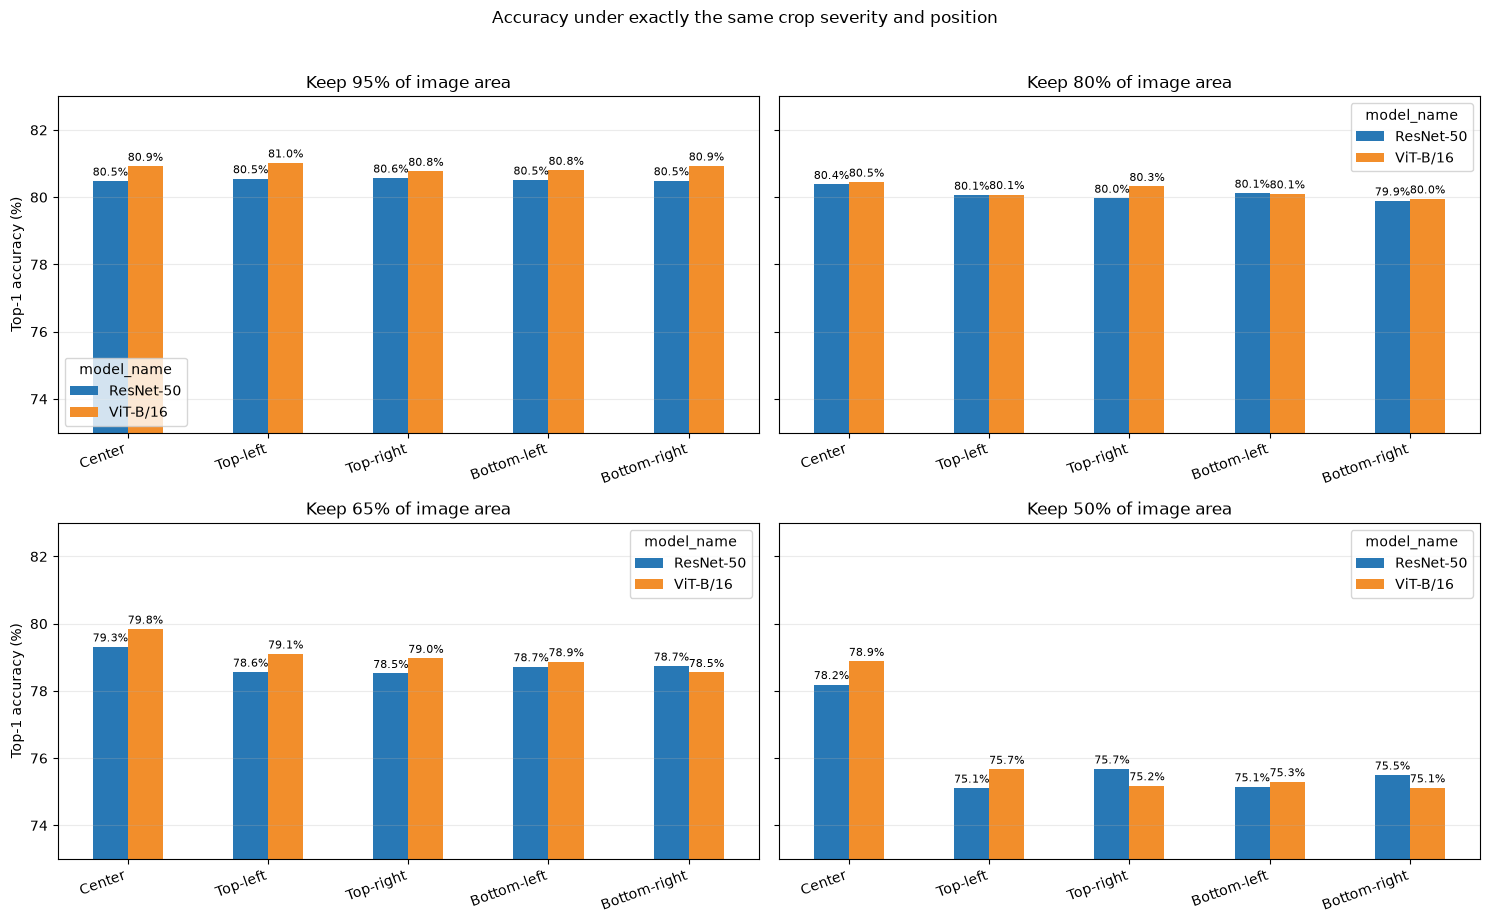

In [13]:
position_order = ['center', 'top_left', 'top_right', 'bottom_left', 'bottom_right']
position_labels = ['Center', 'Top-left', 'Top-right', 'Bottom-left', 'Bottom-right']
fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharey=True)
for axis, severity in zip(axes.flat, sorted(metrics.severity.unique(), reverse=True)):
    subset = metrics[metrics.severity == severity].pivot(
        index='position', columns='model_name', values='perturbed_top1_accuracy_percent'
    ).reindex(position_order)
    subset = subset.rename(columns=model_labels)
    subset.plot(kind='bar', ax=axis, rot=0, color=[colors['resnet50'], colors['vit_b_16']])
    axis.set_xticklabels(position_labels, rotation=20, ha='right')
    axis.set_title(f'Keep {severity:.0%} of image area')
    axis.set_xlabel('')
    axis.set_ylabel('Top-1 accuracy (%)')
    axis.set_ylim(73, 83)
    axis.grid(axis='y', alpha=0.25)
    for container in axis.containers:
        axis.bar_label(container, labels=[f'{value:.1f}%' for value in container.datavalues], padding=2, fontsize=8)
plt.suptitle('Accuracy under exactly the same crop severity and position', y=1.02)
plt.tight_layout()

### What the percentages show

The summary below is computed from the selected run. It focuses on the change from clean images to the strongest shared crop level.

In [14]:
strongest = severity_metrics[severity_metrics.severity == 0.50].set_index('model_name')
print('At 50% retained area (average across five positions):')
for model_name in model_order:
    row = strongest.loc[model_name]
    print(
        f"• {model_labels[model_name]}: Top-1 accuracy falls from "
        f"{row.clean_top1_accuracy_percent:.1f}% to {row.perturbed_top1_accuracy_percent:.1f}%, "
        f"a relative loss of {row.relative_top1_drop_percent:.1f}%."
    )
print('\nOverall pattern: both models lose accuracy as less image area is retained.')
print('The two accuracy curves remain close; neither model has a large robustness advantage on this fixed crop grid.')
print('Center crops preserve more accuracy than corner crops, especially at 50% retained area.')

At 50% retained area (average across five positions):
• ResNet-50: Top-1 accuracy falls from 80.8% to 75.9%, a relative loss of 6.1%.
• ViT-B/16: Top-1 accuracy falls from 80.8% to 76.0%, a relative loss of 5.8%.

Overall pattern: both models lose accuracy as less image area is retained.
The two accuracy curves remain close; neither model has a large robustness advantage on this fixed crop grid.
Center crops preserve more accuracy than corner crops, especially at 50% retained area.
